In [1]:
using LinearAlgebra
using PyPlot
using Trapz
using Calculus
using QuadGK
#some tests with matrices
Bitay=([1 0; 0 1])
A = [1+im 2-im; 2+2 im 3+im]
c = Bitay + A
print(Bitay)
print(A)
print(c)

LoadError: [91mArgumentError: row 2 has mismatched number of columns (expected 2, got 3)[39m

In [2]:
print(1*Matrix(I, 2,2 ))
return A
print(transpose(conj(A)))
x = range(0, 10, length=100)
y = sin.(x)
plot(x, y)

[1 0; 0 1]

LoadError: [91mUndefVarError: A not defined[39m

0.80.005

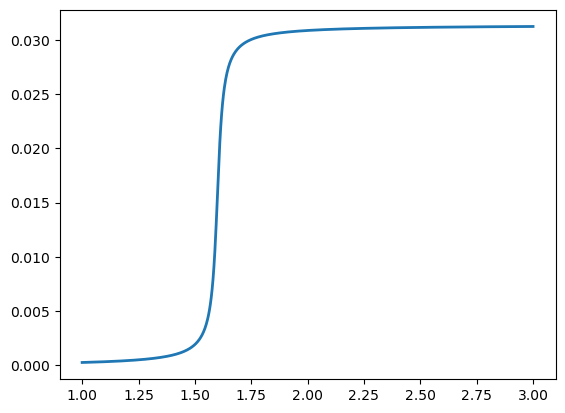

In [40]:
eps1 = 0.8
eps2 =1.2
t = 0.
eta = 10^(-7)
gammal1,gammal2, gammar1, gammar2 = 0.01,0.01,0.01,0.01
emin, emax = -1., 3.

H = eps1
function G_ret_ein(energy::Float64,
        eta::Float64,
        Hamiltonian::Float64,
        gamma_l::Float64,
        gamma_r::Float64
        )
    M = energy + eta*im 
    matrix_self = -1im* (gamma_l+ gamma_r)/2
    return  1/(M - matrix_self - Hamiltonian)
end 
function transmission_ein(G_ret,#::Array{Float64}, complex!
        gamma_l::Float64,
        gamma_r::Float64) # Tr( Γ_L G^A Γ_R G^R)
    
    G_ad =conj(G_ret) # #G_ad = G_ret degga
    final_Matrix = gamma_l* G_ad * gamma_r * G_ret
    return real.(final_Matrix)
end 
function allforT_ein(e::Float64, eta::Float64,H,
        gamma_l::Float64, gamma_r::Float64) #params::Array{Float64})#)
    
    G_r = G_ret_ein(e, eta, H, gamma_l, gamma_r) 
    return transmission_ein(G_r, gamma_l,  gamma_r)
    #Hamiltonian = H_zweiniveau(params[1], params[2], params[3])
    #G_r = G_ret(e, params[4], Hamiltonian, params[5],  params[6],  params[7],  params[8]) 
    #return transmission(G_r,params[5],  params[6],  params[7],  params[8])
end
function IU_ein(u::Float64, H::Float64, eta::Float64,
            gammal::Float64, gammar::Float64)
    emin = -u/2
    emax = (u/2)
    E_list = Array(range(emin, emax, length = 1000))
    TfromE = [allforT_ein( E, eta,H ,gammal1, gammar2 ) for E in E_list]
    return trapz(E_list, TfromE)
    #T_E_list = [allforT(i, [eps1, eps2, t, , eta, gammal1, gammal2, gammar1, gammar2]) for i in E_list]
     #integral(E_list, real.(T_E_list))
end
u_list= Array(range(1.,3., length = 1000))
ifromu = [IU_ein(u,H, eta, gammal1, gammar2) for u in u_list]
plt.plot(
    u_list, ifromu,
    label = "current",
    linewidth = 2 
    )
print(H)
print(gammal1*gammar1/(gammal1*2))

In [3]:
function H_zweiniveau(energy1::Float64,
        energy2::Float64,
        thopping::Float64)
    return Matrix([energy1 thopping; thopping energy2])
end 
function G_ret(energy::Float64,
        eta::Float64,
        Hamiltonian::Array{Float64},
        gamma_l1::Float64,
        gamma_l2::Float64,
        gamma_r1::Float64,
        gamma_r2::Float64)
    Matrix_I_e = (energy + eta*im ) * Matrix(I, 2,2)
    gamma_l = Matrix([gamma_l1 0; 0 gamma_l2]) # for two coupling parameters to both leads
    gamma_r = Matrix([gamma_r1 0 ; 0 gamma_r2])
    matrix_self = -1im* (gamma_l+ gamma_r)/2
    return  inv(Matrix_I_e - matrix_self - Hamiltonian)
end 
function transmission(G_ret,#::Array{Float64}, complex!
        gamma_l1::Float64,
        gamma_l2::Float64,
        gamma_r1::Float64,
        gamma_r2::Float64) # Tr( Γ_L G^A Γ_R G^R)
    gamma_l = Matrix([gamma_l1 0; 0 gamma_l2]) # for two coupling parameters to both leads
    gamma_r = Matrix([gamma_r1 0 ; 0 gamma_r2])
    G_ad =adjoint(G_ret) # #G_ad = G_ret degga
    final_Matrix = gamma_l* G_ad * gamma_r * G_ret
    return real.(tr(final_Matrix))
end 
function allforT(e::Float64,energy1::Float64, energy2::Float64, thopping::Float64, eta::Float64,
        gamma_l1::Float64, gamma_l2::Float64, gamma_r1::Float64, gamma_r2::Float64) #params::Array{Float64})#)
    
    Hamiltonian = H_zweiniveau(energy1, energy2, thopping)
    G_r = G_ret(e, eta, Hamiltonian, gamma_l1, gamma_l2, gamma_r1, gamma_r2) 
    return (transmission(G_r, gamma_l1, gamma_l2, gamma_r1, gamma_r2))
    #Hamiltonian = H_zweiniveau(params[1], params[2], params[3])
    #G_r = G_ret(e, params[4], Hamiltonian, params[5],  params[6],  params[7],  params[8]) 
    #return transmission(G_r,params[5],  params[6],  params[7],  params[8])
end
function integral(x::Array{Float64},
        y::Array{Float64})
    delta_x = [x[i+1] - x[i] for i in 1:(length(x)-1)]
    y_mean = [(y[i]+ y[i+1])/2 for i in 1:(length(x)-1)]
    areas = [delta_x[i]*y_mean[i] for i in 1:(length(x)-1)]
    return sum(areas)
   # return areas
end


integral (generic function with 1 method)

In [31]:

 
function IU(u::Float64, eps1::Float64, eps2::Float64, t::Float64, eta::Float64,
            gammal1::Float64, gammal2::Float64, gammar1::Float64, gammar2::Float64)
    emin = -u/2
    emax = (u/2)
    E_list = Array(range(emin, emax, length = 1000))
    TfromE = [allforT( E, eps1, eps2, t, eta, gammal1, gammal2, gammar1, gammar2 ) for E in E_list]
    return trapz(E_list, TfromE)
    #T_E_list = [allforT(i, [eps1, eps2, t, , eta, gammal1, gammal2, gammar1, gammar2]) for i in E_list]
     #integral(E_list, real.(T_E_list))
end 
    
function I_max( gamma_l1::Float64,
        gamma_l2::Float64,
        gamma_r1::Float64,
        gamma_r2::Float64, 
        H) # Tr( Γ_L G^A Γ_R G^R)
    gamma_l = Matrix([gamma_l1 0; 0 gamma_l2]) # for two coupling parameters to both leads
    gamma_r = Matrix([gamma_r1 0 ; 0 gamma_r2])   

    ei, vec = eigen(H)
    U_deg = vec'
    gamma_l_deg = U_deg*gamma_l * vec
    gamma_r_deg =  U_deg*gamma_r * vec
    I1 = gamma_l_deg[1,1]* gamma_r_deg[1, 1]/(gamma_l_deg[1,1] + gamma_r_deg[1, 1])  
    I2 = gamma_l_deg[2,2]* gamma_r_deg[2, 2]/(gamma_l_deg[2,2] + gamma_r_deg[2, 2])
    return I1 + I2
end
x_q(x)= x


x_q (generic function with 2 methods)

(0.0, 0.0)

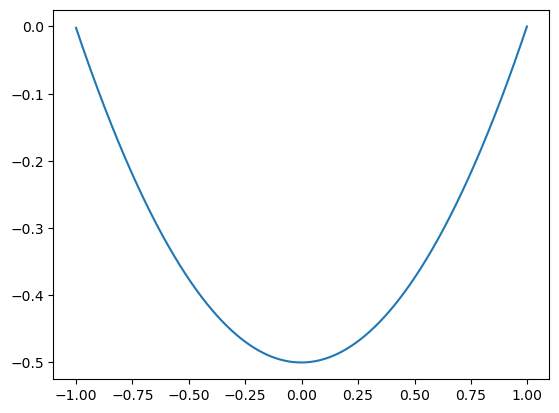

1-element Array{PyCall.PyObject,1}:
 PyObject <matplotlib.lines.Line2D object at 0x7f1e76e6aa00>

In [32]:
x_data = range(-1, 1, length = 1000)
y_data = quadgk(x -> x, -1, 1 )
print(y_data)
 y_int= []
    for i in 1:(length(x_data)-1)
        x_neu  = range(x_data[i], x_data[i+1], length = 10)
        y_neu = x_q(x_neu)
        if i ==1
            push!(y_int, trapz(x_neu, y_neu))
        end
        if i > 1
            s = y_int[i-1] +  trapz(x_neu, y_neu)
            push!(y_int, s)
        end
    end
        plt.plot(x_data[1:end-1], y_int, label= "with second function")

In [23]:
function integral_f(x_data::Array{Float64},energy1::Float64, energy2, thopping, eta, gamma_l1, gamma_l2, gamma_r1, gamma_r2)#params::Array{Float64})
    y_int= []
    for i in 1:(length(x_data)-1)
        x_neu  = range(x_data[i], x_data[i+1], length = 10)
        y_neu = [allforT(x/2, energy1, energy2, thopping, eta, gamma_l1, gamma_l2, gamma_r1, gamma_r2) for x in x_neu]
        if i ==1
            push!(y_int, trapz(x_neu, y_neu))
        end
        if i > 1
            s = y_int[i-1] +  trapz(x_neu, y_neu)
            push!(y_int, s)
        end
    end
        plt.plot(x_data[1:end-1], y_int, label= "with second function")
    return 
end

integral_f (generic function with 1 method)

#### 

Eigen{Float64,Float64,Array{Float64,2},Array{Float64,1}}([0.8, 1.2], [1.0 0.0; 0.0 1.0])Array{Float64,2}

sys:1: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.


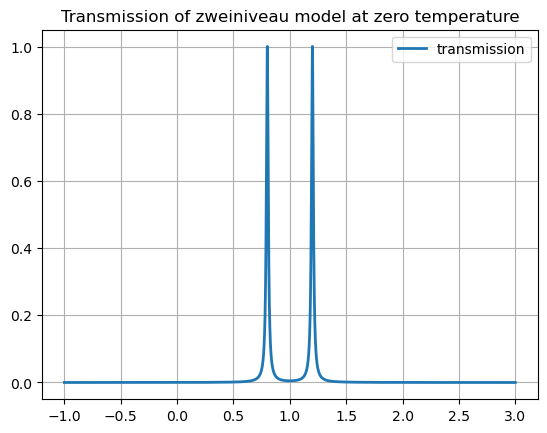

0.01

In [15]:
# plot transmission in dependece of energy
eps1 = 0.8
eps2 =1.2
t = 0.
eta = 10^(-7)
gammal1,gammal2, gammar1, gammar2 = 0.01,0.01,0.01,0.01
emin, emax = -1., 3.

E_list = range(emin, emax, length = 20000)# start: stepsize:end
T_E_list = [allforT( x, eps1, eps2, t, eta, gammal1, gammal2, gammar1, gammar2) for x in E_list]
plt.plot(
    
    E_list, real.(T_E_list),
    label = "transmission",
    linewidth = 2 
    )
plt.legend()
plt.title("Transmission of zweiniveau model at zero temperature")
plt.grid("true")
plt.savefig("transmission_zweiniv.pdf")
plt.show()

H = H_zweiniveau(eps1, eps2, t)
print(eigen(H), typeof(H))
I_max( gammal1,
        gammal2,
        gammar1,
        gammar2, 
        H)

In [8]:
#IU(u_list, eps1, eps2, t, eta, gammal1, gammal2, gammar1, gammar2)

sys:1: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.


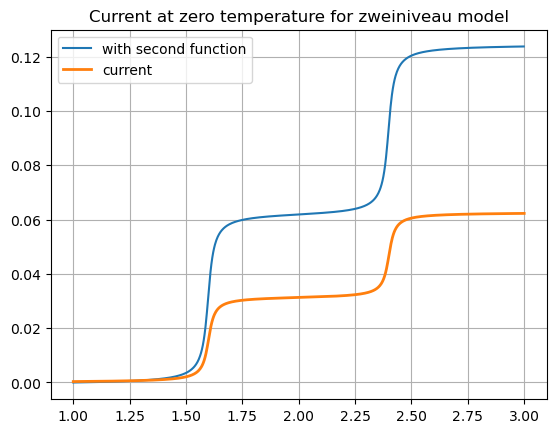

In [24]:
u_list= Array(range(1.,3., length = 1000))

integral_f( u_list,eps1, eps2, t, eta, gammal1, gammal2, gammar1, gammar2)

ifromu = [IU(u,eps1, eps2, t, eta, gammal1, gammal2, gammar1, gammar2) for u in u_list]
plt.plot(
    u_list, ifromu,
    label = "current",
    linewidth = 2 
    )
plt.legend()
plt.title("Current at zero temperature for zweiniveau model")
plt.grid("true")
plt.savefig("IU_zweiniv.pdf")
plt.show()
#print( "I_max =", gammal1*gammar1/(gammal1+ gammar1))
# in the formula gamma is a matrix

In [10]:
function fermi(e,#::Array{Float64},
        mu_s, phi_s, temp_s)
    return 1/(exp((e- mu_s - phi_s)/temp_s)+ 1) 
end
function to_integrate(e,#::Array{Float64},
        transm,#::Array{Float64},
        mu_l, phi_l, temp_l, mu_r, phi_r, temp_r )
    t_re= transm
    fermi_l = [fermi(energy,  mu_l, phi_l, temp_l) for energy in e]
    fermi_r = [fermi(energy,  mu_r, phi_r, temp_r) for energy in e] 
    return Array([t_re[i]*(fermi_l[i] - fermi_r[i]) for i in 1:length(e)])
end
function IU_temp(u::Float64,
         eps1, eps2, t, eta, gammal1, gammal2, gammar1, gammar2, mu_l, phi_l, temp_l, mu_r, phi_r, temp_r)
    emin = -u/2
    emax = (u/2)
    E_list = range(emin, emax, length = 2000)
    T_E_list = [allforT(i, eps1, eps2, t, eta, gammal1, gammal2, gammar1, gammar2) for i in E_list]
    return trapz(E_list, to_integrate(E_list, T_E_list, mu_l, phi_l, temp_l, mu_r, phi_r, temp_r ))
end 


IU_temp (generic function with 1 method)

sys:1: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.


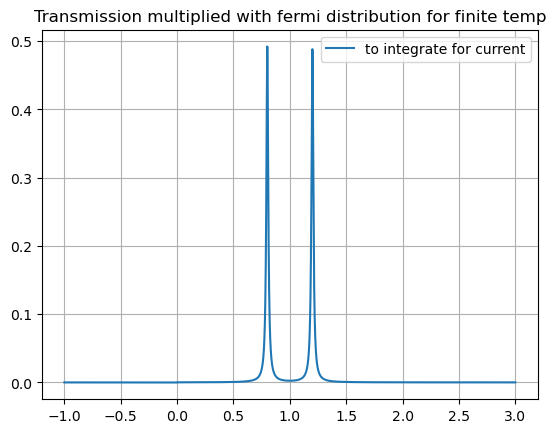

In [11]:
mu_l , phi_l, temp_l = 0.0, 0.0, 25
mu_r, phi_r, temp_r = 0., 0., 0 # wenn die rechte Temp höher ist, wird die differenz der fermi funktionen negativ
# d.h. Kurve ist gespiegelt
plt.plot( E_list,
    to_integrate(E_list, T_E_list, mu_l, phi_l, temp_l, mu_r, phi_r, temp_r ), 
    label = "to integrate for current"
    )
plt.legend()
plt.title("Transmission multiplied with fermi distribution for finite temp")
plt.grid("true")
plt.savefig("transm and fermi for finite temp.pdf")
plt.show()



sys:1: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.


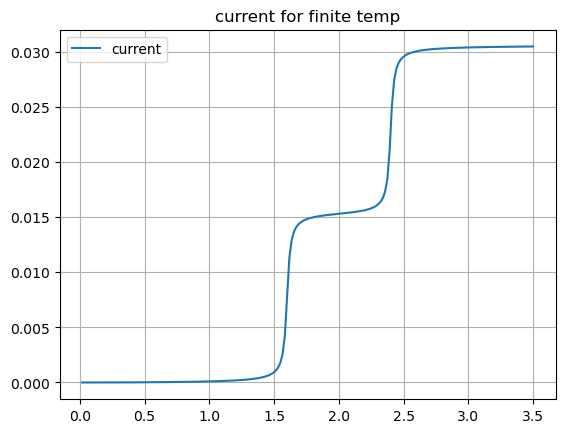

In [12]:
u1_list= range(0.,3.5, length = 200)
iu_list = [IU_temp(u, eps1, eps2, t, eta, gammal1, gammal2, gammar1,
    gammar2, mu_l, phi_l, temp_l, mu_r, phi_r, temp_r) for u in u1_list]

plt.plot(
    u1_list, 
    iu_list, 
    label = "current"
    )
plt.legend()
plt.title("current for finite temp")
plt.grid("true")
plt.savefig("transm and fermi for finite temp.pdf")
plt.show()

In [13]:
elem_ladung = 1.60217733* 10^(-19)
h_quer = 6.626069*10^(-34)/(2*pi)
#print(2*elem_ladung/h_quer)


function calculate_slope( x_data, y_data)
    f(x) = interpolate(x_data, y_data)(x)
    df= derivative(f)
    return [f(x) for x in x_data]
end
function calculate_slope2(x,#::Array{Float64},
        y )#::Array{Float64})
    df = [(x[i+ 1] - x[i])/(y[i+1]- y[i]) for i in 1:(length(x)- 2)]
    return df
end

calculate_slope2 (generic function with 1 method)

In [14]:
#plt.plot(u_list, calculate_slope2(u_list, ifromu))